# StyleBot 04: aprendizaje no supervisado y recomendador

**Responsable:** Luis Angel Mendosa Gaytán (simulación y aprendizaje por refuerzo; en la primera entrega, aprendizaje no supervisado).

Este notebook conserva las celdas comunes del líder (secciones 1 a 4, sin cambios) y después agrega mi parte, que corresponde a las secciones **5 Aprendizaje no supervisado** y **6 Sistema de recomendación** de `E1_StyleBot.ipynb`:

- K-Means con 10 grupos y ejemplos de cada grupo.
- Visualización t-SNE.
- Recomendador que devuelve las cinco prendas más parecidas a una imagen de consulta.
- Evaluación con Precision@5 y comparación contra recomendaciones aleatorias.
- Explicación de resultados y fuentes.

**Cómo usarlo:** abre el archivo en Google Colab y ejecuta las celdas de arriba hacia abajo (Entorno de ejecución > Ejecutar todas). Basta el entorno normal de CPU; tarda pocos minutos. La primera ejecución necesita Internet para descargar Fashion-MNIST.

**Uso de las categorías reales:** las categorías reales solo se usan para analizar y evaluar los resultados, no para escoger artificialmente los grupos ni las recomendaciones.

- K-Means recibe solo las 50 componentes de PCA (`kmeans.fit(Z_train)`), sin `y_train`.
- El recomendador busca vecinos solo con las características de las imágenes; la categoría nunca entra en la búsqueda.
- Las categorías se usan después para nombrar los grupos por su categoría mayoritaria, calcular pureza, ARI, NMI y Precision@5, y elegir ejemplos de aciertos y fallos.
- k = 10 lo fija el plan del equipo (una por categoría); se revisan otros valores de k con inercia y silueta, que no usan etiquetas.

**Otras reglas:** PCA y K-Means se ajustan solo con entrenamiento. Las variantes del recomendador se comparan en validación y la prueba se usa una sola vez al final.

## 1 Carga común para todo el equipo

    Esta celda define las categorías y las funciones. Todos deben conservarla igual. `X` contiene imágenes y `y` las categorías correctas.

    La prueba oficial tiene 10,000 imágenes. De las otras 60,000 apartamos 20 % para validación: quedan 48,000 para entrenamiento y 12,000 para validación. `stratify` conserva la proporción de las categorías y la semilla 42 fija la división. Los píxeles ya quedan normalizados entre 0 y 1; no vuelvas a dividirlos entre 255.

In [1]:
import numpy as np
from sklearn.model_selection import train_test_split

SEMILLA = 42
CATEGORIAS = [
    "Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
    "Sandalia", "Camisa", "Tenis", "Bolso", "Botín"
]

def preparar_datos_stylebot(X_base, y_base, X_prueba, y_prueba):
    """Divide los 60,000 ejemplos originales y conserva la prueba oficial."""
    assert X_base.shape == (60000, 28, 28)
    assert y_base.shape == (60000,)
    assert X_prueba.shape == (10000, 28, 28)
    assert y_prueba.shape == (10000,)
    assert X_base.dtype == np.uint8 and X_prueba.dtype == np.uint8

    # Los índices permiten identificar exactamente las imágenes de cada parte.
    indices = np.arange(len(y_base), dtype=np.int64)
    idx_train, idx_val = train_test_split(
        indices, test_size=0.20, random_state=SEMILLA, stratify=y_base
    )

    # Normalizar una sola vez: uint8 de 0 a 255 -> float32 de 0 a 1.
    datos = {
        "X_train": X_base[idx_train].astype(np.float32) / np.float32(255.0),
        "y_train": y_base[idx_train].copy(),
        "X_val": X_base[idx_val].astype(np.float32) / np.float32(255.0),
        "y_val": y_base[idx_val].copy(),
        "X_test": X_prueba.astype(np.float32) / np.float32(255.0),
        "y_test": y_prueba.copy(),
        "idx_train": idx_train,
        "idx_val": idx_val,
        # Estos índices pertenecen al archivo de prueba, no al de entrenamiento.
        "idx_test": np.arange(len(y_prueba), dtype=np.int64),
    }
    return datos

def cargar_datos_stylebot():
    """Descarga Fashion-MNIST automáticamente mediante TensorFlow/Keras."""
    from tensorflow.keras.datasets import fashion_mnist
    (X_base, y_base), (X_prueba, y_prueba) = fashion_mnist.load_data()
    return preparar_datos_stylebot(X_base, y_base, X_prueba, y_prueba)


## 2 Descargar y preparar Fashion MNIST

    Ejecuta la siguiente celda. `fashion_mnist.load_data()` descarga automáticamente los archivos oficiales a través de TensorFlow/Keras.

    Esperamos estas formas: entrenamiento `(48000, 28, 28)`, validación `(12000, 28, 28)` y prueba `(10000, 28, 28)`. La descarga puede tardar la primera vez.

In [2]:
datos = cargar_datos_stylebot()
X_train, y_train = datos["X_train"], datos["y_train"]
X_val, y_val = datos["X_val"], datos["y_val"]
X_test, y_test = datos["X_test"], datos["y_test"]

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validación:   ", X_val.shape, y_val.shape)
print("Prueba:       ", X_test.shape, y_test.shape)
print("Píxeles:", X_train.dtype, "de", X_train.min(), "a", X_train.max())


Entrenamiento: (48000, 28, 28) (48000,)
Validación:    (12000, 28, 28) (12000,)
Prueba:        (10000, 28, 28) (10000,)
Píxeles: float32 de 0.0 a 1.0


## 3 Comprobar la división y los valores

    Las instrucciones `assert` detienen la ejecución si algo no coincide con lo esperado. Conservamos los índices de entrenamiento y validación para verificar que no se mezclaron. Los índices de prueba pertenecen a un archivo diferente.

    Revisamos forma, cantidad, rango, valores no finitos y categorías. Esto no equivale a una inspección exhaustiva de daños visuales ni a una búsqueda de duplicados de contenido.

In [3]:
# Esta comprobación NO evalúa modelos: verifica la preparación de datos.
assert len(np.intersect1d(datos["idx_train"], datos["idx_val"])) == 0
assert len(np.union1d(datos["idx_train"], datos["idx_val"])) == 60000

comprobaciones = []
for nombre, X, y, cantidad in [
    ("entrenamiento", X_train, y_train, 48000),
    ("validacion", X_val, y_val, 12000),
    ("prueba", X_test, y_test, 10000),
]:
    assert X.shape == (cantidad, 28, 28)
    assert y.shape == (cantidad,)
    assert X.dtype == np.float32
    assert np.isfinite(X).all()
    assert X.min() >= 0.0 and X.max() <= 1.0
    assert np.isin(y, np.arange(10)).all()
    conteos = np.bincount(y, minlength=10)
    assert np.all(conteos == cantidad // 10)
    comprobaciones.append({
        "conjunto": nombre, "imagenes": cantidad,
        "forma_imagen": "28x28", "tipo_pixeles": str(X.dtype),
        "minimo": float(X.min()), "maximo": float(X.max()),
        "valores_no_finitos": int((~np.isfinite(X)).sum()),
        "etiquetas_invalidas": int((~np.isin(y, np.arange(10))).sum()),
    })
    print(nombre, "OK:", cantidad, "imágenes;", conteos.tolist(), "por categoría")

print("OK: entrenamiento y validación no comparten índices.")
print("La prueba conserva las 10,000 imágenes del archivo oficial de prueba.")
print("Estas revisiones no demuestran ausencia de imágenes duplicadas o problemas visuales.")


entrenamiento OK: 48000 imágenes; [4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800] por categoría
validacion OK: 12000 imágenes; [1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200] por categoría
prueba OK: 10000 imágenes; [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000] por categoría
OK: entrenamiento y validación no comparten índices.
La prueba conserva las 10,000 imágenes del archivo oficial de prueba.
Estas revisiones no demuestran ausencia de imágenes duplicadas o problemas visuales.


## 4 Ver las categorías y sus cantidades

    Los números tienen el mismo significado para todos los integrantes. Camiseta es 0 y camisa es 6; no deben intercambiarse. Con esta división esperamos 4,800 imágenes de entrenamiento, 1,200 de validación y 1,000 de prueba por categoría.

In [4]:
print("ID | Categoría | Entrenamiento | Validación | Prueba")
conteo_clases = []
for identificador, categoria in enumerate(CATEGORIAS):
    fila = {
        "id": identificador, "categoria": categoria,
        "entrenamiento": int(np.sum(y_train == identificador)),
        "validacion": int(np.sum(y_val == identificador)),
        "prueba": int(np.sum(y_test == identificador)),
    }
    conteo_clases.append(fila)
    print(f"{identificador:2} | {categoria:9} | {fila['entrenamiento']:5} | {fila['validacion']:5} | {fila['prueba']:5}")


ID | Categoría | Entrenamiento | Validación | Prueba
 0 | Camiseta  |  4800 |  1200 |  1000
 1 | Pantalón  |  4800 |  1200 |  1000
 2 | Suéter    |  4800 |  1200 |  1000
 3 | Vestido   |  4800 |  1200 |  1000
 4 | Abrigo    |  4800 |  1200 |  1000
 5 | Sandalia  |  4800 |  1200 |  1000
 6 | Camisa    |  4800 |  1200 |  1000
 7 | Tenis     |  4800 |  1200 |  1000
 8 | Bolso     |  4800 |  1200 |  1000
 9 | Botín     |  4800 |  1200 |  1000


## 5 Confirmar que la división es la del equipo

Se comparan las huellas SHA-256 de los índices con las publicadas por el líder en `datos/protocolo_datos.json`. Si coinciden, este notebook usa exactamente las mismas imágenes que el resto del equipo.

In [5]:
import hashlib

# Huellas publicadas por el líder en datos/protocolo_datos.json
HUELLAS_EQUIPO = {
    "idx_train": "1c0cffec1476c830767b282ef3e3354d14cb1e3e2ecb436f13ee8537f0de19c9",
    "idx_val": "e0f8e8bab9913b94050db422b1a42d5223f440f15b110f7ae060debf1332089f",
    "idx_test": "9e1c19b3fdc185411bd1a987deb6a9fda2531116aac060a84c4d878854d1c099",
}
for nombre, esperada in HUELLAS_EQUIPO.items():
    obtenida = hashlib.sha256(datos[nombre].astype("<i8").tobytes()).hexdigest()
    print(f"{nombre}: {'coincide' if obtenida == esperada else 'NO coincide'}")
    assert obtenida == esperada, (
        "La división no coincide con la del equipo. Revisar versiones con el líder antes de seguir."
    )
print("OK: misma división que el resto del equipo.")

idx_train: coincide
idx_val: coincide
idx_test: coincide
OK: misma división que el resto del equipo.


## 6 Funciones de agrupamiento y recomendación

Las mismas funciones están en `src/recomendador_stylebot.py` para la integración.

- `ajustar_pca`: PCA ajustado solo con entrenamiento.
- `ajustar_kmeans` y `metricas_agrupamiento`: K-Means y su comparación contra las categorías reales (pureza, ARI y NMI).
- `construir_recomendador` y `recomendar`: búsqueda de las prendas más cercanas en el catálogo.
- `recomendar_mismo_grupo`: variante que busca solo dentro del mismo grupo de K-Means.
- `recomendaciones_aleatorias` y `precision_en_k`: línea base y métrica.

In [6]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.neighbors import NearestNeighbors

SEMILLA = 42


def a_vectores(X):
    """(n, 28, 28) -> (n, 784). No vuelve a normalizar: los píxeles ya están entre 0 y 1."""
    return X.reshape(len(X), -1)


def ajustar_pca(X_train, n_componentes=50, semilla=SEMILLA):
    """Ajusta PCA solo con entrenamiento. Validación y prueba únicamente se transforman."""
    pca = PCA(n_components=n_componentes, random_state=semilla)
    pca.fit(a_vectores(X_train))
    return pca


def ajustar_kmeans(Z_train, k=10, semilla=SEMILLA, n_init=10):
    """K-Means sobre las características de entrenamiento."""
    modelo = KMeans(n_clusters=k, n_init=n_init, random_state=semilla)
    modelo.fit(Z_train)
    return modelo


def tabla_contingencia(grupos, y, k=10, n_categorias=10):
    """Filas = grupos de K-Means, columnas = categorías reales."""
    tabla = np.zeros((k, n_categorias), dtype=np.int64)
    np.add.at(tabla, (grupos, y), 1)
    return tabla


def metricas_agrupamiento(grupos, y, k=10):
    """Pureza, ARI y NMI. Las etiquetas solo se usan para evaluar, no para agrupar."""
    tabla = tabla_contingencia(grupos, y, k)
    return {
        "pureza": float(tabla.max(axis=1).sum() / tabla.sum()),
        "ari": float(adjusted_rand_score(y, grupos)),
        "nmi": float(normalized_mutual_info_score(y, grupos)),
    }


def construir_recomendador(Z_catalogo, metrica="cosine"):
    """Índice de vecinos más cercanos sobre el catálogo (entrenamiento)."""
    return NearestNeighbors(metric=metrica, algorithm="brute").fit(Z_catalogo)


def recomendar(indice, Z_consultas, k=5):
    """Devuelve, para cada consulta, las posiciones de las k prendas más parecidas del catálogo."""
    _, posiciones = indice.kneighbors(Z_consultas, n_neighbors=k)
    return posiciones


def recomendar_mismo_grupo(Z_catalogo, grupos_catalogo, Z_consultas, grupos_consultas,
                           k=5, metrica="cosine"):
    """Variante: busca vecinos solo entre las prendas del mismo grupo de K-Means."""
    posiciones = np.empty((len(Z_consultas), k), dtype=np.int64)
    for g in np.unique(grupos_consultas):
        en_grupo = np.flatnonzero(grupos_catalogo == g)
        consultas = np.flatnonzero(grupos_consultas == g)
        indice = construir_recomendador(Z_catalogo[en_grupo], metrica)
        _, locales = indice.kneighbors(Z_consultas[consultas], n_neighbors=k)
        posiciones[consultas] = en_grupo[locales]
    return posiciones


def recomendaciones_aleatorias(n_consultas, n_catalogo, k=5, semilla=SEMILLA):
    """Línea base: k prendas del catálogo elegidas al azar, sin repetir dentro de cada consulta."""
    rng = np.random.default_rng(semilla)
    return np.stack([rng.choice(n_catalogo, size=k, replace=False) for _ in range(n_consultas)])


def aciertos(y_consultas, y_catalogo, posiciones):
    """Matriz booleana: True si la recomendación es de la misma categoría que la consulta."""
    return y_catalogo[posiciones] == y_consultas[:, None]


def precision_en_k(y_consultas, y_catalogo, posiciones):
    """Precision@k promedio: fracción de recomendaciones de la misma categoría."""
    return float(aciertos(y_consultas, y_catalogo, posiciones).mean())

# Carpeta de resultados de esta parte
from pathlib import Path
import csv

CARPETA_SALIDA = Path("StyleBot_agrupamiento_generado")
for subcarpeta in ["resultados/tablas", "resultados/graficas"]:
    (CARPETA_SALIDA / subcarpeta).mkdir(parents=True, exist_ok=True)

def guardar_csv(nombre, filas):
    ruta = CARPETA_SALIDA / "resultados/tablas" / nombre
    with ruta.open("w", newline="", encoding="utf-8-sig") as archivo:
        escritor = csv.DictWriter(archivo, fieldnames=list(filas[0].keys()))
        escritor.writeheader()
        escritor.writerows(filas)

def guardar_figura(fig, nombre):
    fig.savefig(CARPETA_SALIDA / "resultados/graficas" / nombre, dpi=150, bbox_inches="tight")

## 7 Vectores de 784 píxeles y PCA de 50 componentes

Estas dos celdas son las mismas de `02_caracteristicas.ipynb` (responsable de características), para que todos usemos exactamente la misma representación. Cada imagen de 28 x 28 se aplana en 784 valores y PCA los reduce a 50 componentes. PCA se ajusta **solo** con entrenamiento; validación y prueba solo se transforman.

In [7]:
def aplanar_imagenes(X):
    return X.reshape(X.shape[0], -1)

X_train_flat = aplanar_imagenes(X_train)
X_val_flat = aplanar_imagenes(X_val)
X_test_flat = aplanar_imagenes(X_test)
print("Forma aplanada:", X_train_flat.shape) # Debe dar (48000, 784)

Forma aplanada: (48000, 784)


In [8]:
from sklearn.decomposition import PCA

# Función reutilizable para preparar PCA (ajustando SOLO con entrenamiento)
def aplicar_pca(X_train_f, X_val_f, X_test_f, n_componentes=50):
    pca = PCA(n_components=n_componentes, random_state=42)

    # Regla de oro: fit_transform solo en entrenamiento, transform en validación y prueba
    X_train_pca = pca.fit_transform(X_train_f)
    X_val_pca = pca.transform(X_val_f)
    X_test_pca = pca.transform(X_test_f)

    varianza = pca.explained_variance_ratio_.sum()
    print(f"Varianza conservada con {n_componentes} componentes: {varianza:.4f} ({varianza*100:.2f}%)")
    return X_train_pca, X_val_pca, X_test_pca, pca

# Ejecutar PCA
X_train_pca, X_val_pca, X_test_pca, modelo_pca = aplicar_pca(X_train_flat, X_val_flat, X_test_flat, 50)
print("Forma de entrenamiento con PCA:", X_train_pca.shape) # Debe dar (48000, 50)

Varianza conservada con 50 componentes: 0.8627 (86.27%)
Forma de entrenamiento con PCA: (48000, 50)


In [9]:
import time

# Nombres cortos para el resto del notebook
pca = modelo_pca
Z_train, Z_val, Z_test = X_train_pca, X_val_pca, X_test_pca
print("Características para agrupar y recomendar:", Z_train.shape, Z_val.shape, Z_test.shape)

Características para agrupar y recomendar: (48000, 50) (12000, 50) (10000, 50)


## 8 Agrupamiento con K-Means

### 8.1 Ejemplo pequeño

Primera prueba rápida de K-Means: 2,000 imágenes de entrenamiento elegidas al azar y 10 grupos. Sirve para confirmar que el procedimiento funciona antes de usar las 48,000 imágenes. Se muestran seis imágenes de cuatro grupos; K-Means no recibe las etiquetas.

Imágenes por grupo: [253, 198, 193, 322, 211, 157, 240, 256, 94, 76]


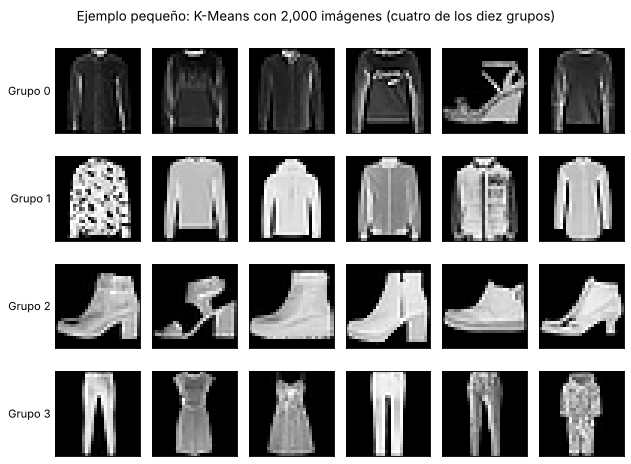

In [10]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(SEMILLA)
muestra_pequena = rng.choice(len(Z_train), size=2000, replace=False)
kmeans_pequeno = ajustar_kmeans(Z_train[muestra_pequena], k=10, n_init=10)
grupos_pequenos = kmeans_pequeno.labels_
print("Imágenes por grupo:", np.bincount(grupos_pequenos, minlength=10).tolist())

fig, ejes = plt.subplots(4, 6, figsize=(8, 6))
for fila, g in enumerate(range(4)):
    elegidas = rng.choice(np.flatnonzero(grupos_pequenos == g), size=6, replace=False)
    for j, posicion in enumerate(elegidas):
        ejes[fila, j].imshow(X_train[muestra_pequena[posicion]], cmap="gray", vmin=0, vmax=1)
        ejes[fila, j].set_xticks([]); ejes[fila, j].set_yticks([])
    ejes[fila, 0].set_ylabel(f"Grupo {g}", rotation=0, ha="right", va="center")
fig.suptitle("Ejemplo pequeño: K-Means con 2,000 imágenes (cuatro de los diez grupos)")
fig.tight_layout()
guardar_figura(fig, "kmeans_ejemplo_pequeno.png")
plt.show(); plt.close(fig)

### 8.2 Revisar varios números de grupos

Usamos 10 grupos porque el dataset tiene 10 categorías, pero antes revisamos cómo cambian la inercia y la silueta con otros valores. La silueta se calcula con una muestra de 5,000 imágenes de entrenamiento para que sea rápida. Esta revisión es solo de contexto: no usa las etiquetas.

k= 4  inercia=   1554614.2  silueta=0.2222
k= 6  inercia=   1313210.1  silueta=0.2028
k= 8  inercia=   1175057.2  silueta=0.2196
k=10  inercia=   1086461.5  silueta=0.1786
k=12  inercia=   1000047.5  silueta=0.1850
k=14  inercia=    941220.1  silueta=0.1779


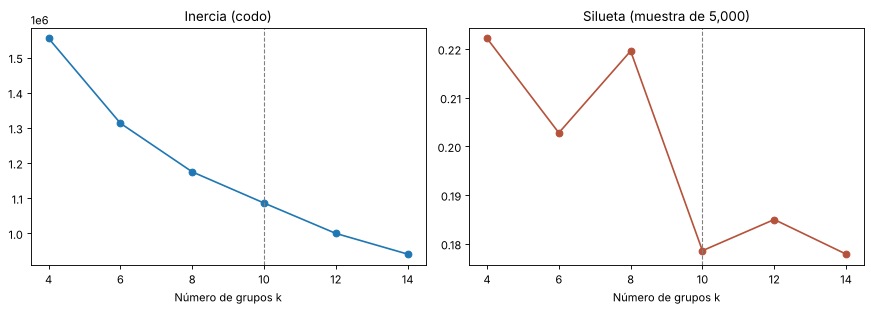

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

rng = np.random.default_rng(SEMILLA)
muestra_sil = rng.choice(len(Z_train), size=5000, replace=False)

valores_k = [4, 6, 8, 10, 12, 14]
revision_k = []
for k in valores_k:
    modelo_k = ajustar_kmeans(Z_train, k=k, n_init=3)
    sil = silhouette_score(Z_train[muestra_sil], modelo_k.labels_[muestra_sil])
    revision_k.append({"k": k, "inercia": round(float(modelo_k.inertia_), 1), "silueta_muestra": round(float(sil), 4)})
    print(f"k={k:2}  inercia={modelo_k.inertia_:12.1f}  silueta={sil:.4f}")
guardar_csv("kmeans_revision_k.csv", revision_k)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].plot(valores_k, [f["inercia"] for f in revision_k], marker="o")
ejes[0].set_title("Inercia (codo)"); ejes[0].set_xlabel("Número de grupos k")
ejes[1].plot(valores_k, [f["silueta_muestra"] for f in revision_k], marker="o", color="#b5523b")
ejes[1].set_title("Silueta (muestra de 5,000)"); ejes[1].set_xlabel("Número de grupos k")
for eje in ejes:
    eje.axvline(10, color="gray", linestyle="--", linewidth=1)
fig.tight_layout()
guardar_figura(fig, "kmeans_revision_k.png")
plt.show(); plt.close(fig)

### 8.3 K-Means con 10 grupos

K-Means no conoce las categorías. Después de agrupar, comparamos los grupos con las categorías reales:

- **Pureza:** porcentaje de imágenes que pertenecen a la categoría mayoritaria de su grupo.
- **ARI** (índice de Rand ajustado): 0 equivale a agrupar al azar y 1 a coincidir perfectamente con las categorías.
- **NMI** (información mutua normalizada): de 0 a 1, cuánto informan los grupos sobre la categoría.

Validación se asigna a grupos con `predict`, sin volver a ajustar.

K-Means ajustado en 1.1 s
entrenamiento  pureza=0.552  ARI=0.347  NMI=0.511
validacion     pureza=0.558  ARI=0.347  NMI=0.512

Grupo | Imágenes | Categoría mayoritaria | % | Segunda categoría | %
    0 |     7265 | Pantalón              |  59.6 | Vestido           |  35.5
    1 |     5236 | Tenis                 |  71.4 | Sandalia          |  21.9
    2 |     2075 | Bolso                 |  94.9 | Camiseta          |   1.3
    3 |     6226 | Sandalia              |  48.4 | Camisa            |   9.9
    4 |     7708 | Abrigo                |  37.2 | Suéter            |  37.0
    5 |     5933 | Camisa                |  27.7 | Suéter            |  23.6
    6 |     2339 | Botín                 |  90.3 | Sandalia          |   8.7
    7 |     5881 | Camiseta              |  45.9 | Vestido           |  23.0
    8 |     3447 | Botín                 |  68.6 | Tenis             |  18.1
    9 |     1890 | Bolso                 |  93.5 | Camisa            |   2.9


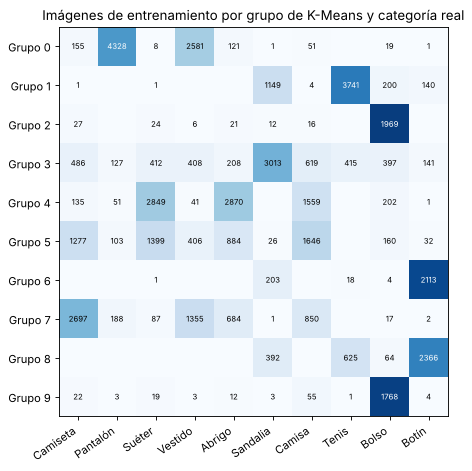

In [12]:
inicio = time.time()
kmeans = ajustar_kmeans(Z_train, k=10, n_init=10)
grupos_train = kmeans.labels_
grupos_val = kmeans.predict(Z_val)
print(f"K-Means ajustado en {time.time() - inicio:.1f} s")

filas_metricas = []
for nombre, grupos, y in [("entrenamiento", grupos_train, y_train), ("validacion", grupos_val, y_val)]:
    m = metricas_agrupamiento(grupos, y)
    filas_metricas.append({"conjunto": nombre, **{c: round(v, 4) for c, v in m.items()}})
    print(f"{nombre:14} pureza={m['pureza']:.3f}  ARI={m['ari']:.3f}  NMI={m['nmi']:.3f}")
guardar_csv("kmeans_metricas.csv", filas_metricas)

tabla = tabla_contingencia(grupos_train, y_train)
resumen_grupos = []
print("\nGrupo | Imágenes | Categoría mayoritaria | % | Segunda categoría | %")
for g in range(10):
    orden = np.argsort(tabla[g])[::-1]
    total = int(tabla[g].sum())
    fila = {
        "grupo": g, "imagenes": total,
        "categoria_mayoritaria": CATEGORIAS[orden[0]], "porcentaje_mayoritaria": round(100 * tabla[g, orden[0]] / total, 1),
        "segunda_categoria": CATEGORIAS[orden[1]], "porcentaje_segunda": round(100 * tabla[g, orden[1]] / total, 1),
    }
    resumen_grupos.append(fila)
    print(f"{g:5} | {total:8} | {fila['categoria_mayoritaria']:21} | {fila['porcentaje_mayoritaria']:5} | "
          f"{fila['segunda_categoria']:17} | {fila['porcentaje_segunda']:5}")
guardar_csv("kmeans_resumen_grupos.csv", resumen_grupos)
guardar_csv("kmeans_contingencia_entrenamiento.csv",
            [{"grupo": g, **{CATEGORIAS[c]: int(tabla[g, c]) for c in range(10)}} for g in range(10)])

fig, ax = plt.subplots(figsize=(10, 6))
proporcion = tabla / tabla.sum(axis=1, keepdims=True)
ax.imshow(proporcion, cmap="Blues", vmin=0, vmax=1)
for g in range(10):
    for c in range(10):
        if tabla[g, c] > 0:
            ax.text(c, g, tabla[g, c], ha="center", va="center", fontsize=7,
                    color="white" if proporcion[g, c] > 0.5 else "black")
ax.set_xticks(range(10), CATEGORIAS, rotation=35, ha="right")
ax.set_yticks(range(10), [f"Grupo {g}" for g in range(10)])
ax.set_title("Imágenes de entrenamiento por grupo de K-Means y categoría real")
fig.tight_layout()
guardar_figura(fig, "kmeans_contingencia.png")
plt.show(); plt.close(fig)

### 8.4 Ejemplos de cada grupo

Ocho imágenes de entrenamiento elegidas al azar dentro de cada grupo. El título indica la categoría mayoritaria del grupo.

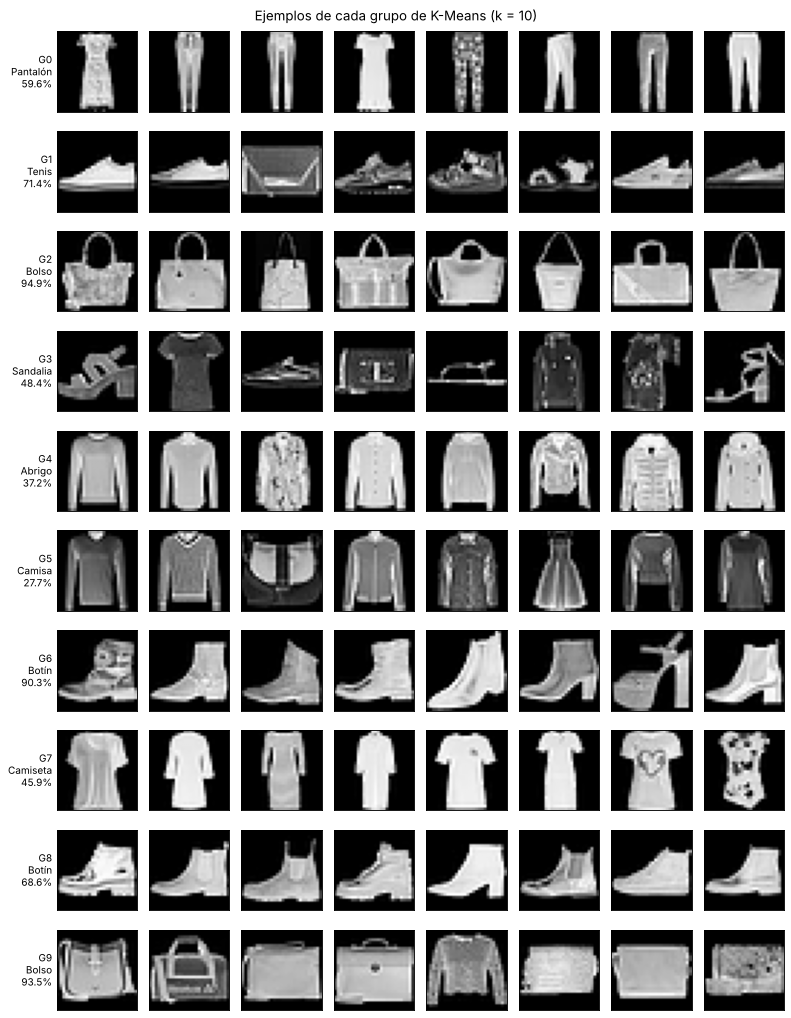

In [13]:
rng = np.random.default_rng(SEMILLA)
fig, ejes = plt.subplots(10, 8, figsize=(10, 13))
for g in range(10):
    elegidas = rng.choice(np.flatnonzero(grupos_train == g), size=8, replace=False)
    for j, indice in enumerate(elegidas):
        ejes[g, j].imshow(X_train[indice], cmap="gray", vmin=0, vmax=1)
        ejes[g, j].set_xticks([]); ejes[g, j].set_yticks([])
    r = resumen_grupos[g]
    ejes[g, 0].set_ylabel(f"G{g}\n{r['categoria_mayoritaria']}\n{r['porcentaje_mayoritaria']}%",
                          rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Ejemplos de cada grupo de K-Means (k = 10)")
fig.tight_layout()
guardar_figura(fig, "kmeans_ejemplos_grupos.png")
plt.show(); plt.close(fig)

## 9 Visualización t-SNE

t-SNE proyecta las 50 componentes en dos dimensiones para ver qué prendas quedan cerca. Se usa una muestra de 3,000 imágenes de entrenamiento porque t-SNE es lento con las 48,000. t-SNE sirve para explorar visualmente: las distancias grandes entre zonas del mapa no deben interpretarse literalmente.

A la izquierda, los colores son las categorías reales; a la derecha, los grupos de K-Means.

t-SNE calculado en 6.3 s


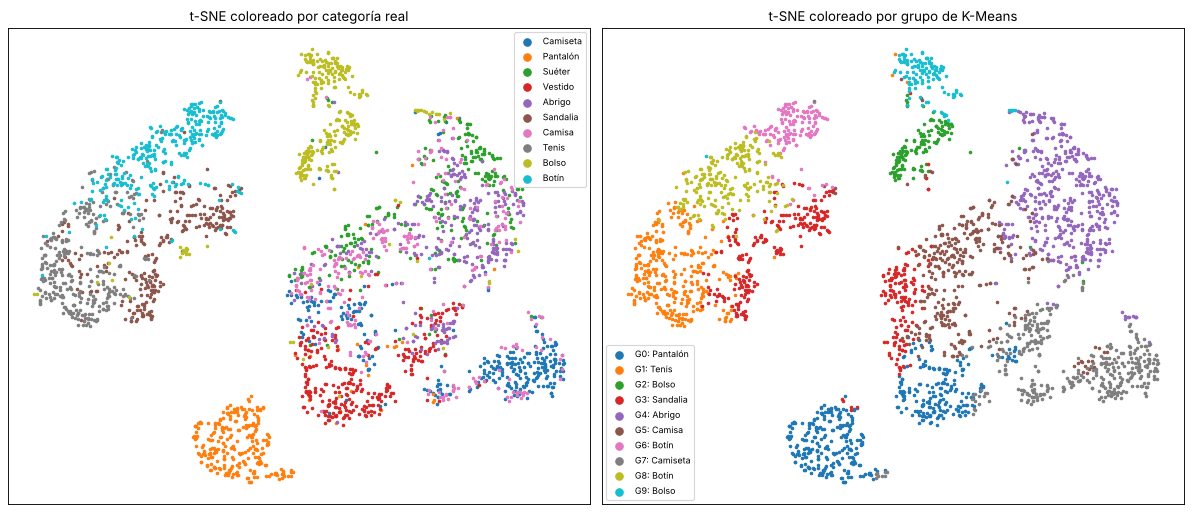

In [14]:
from sklearn.manifold import TSNE

rng = np.random.default_rng(SEMILLA)
muestra_tsne = rng.choice(len(Z_train), size=3000, replace=False)
inicio = time.time()
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
            max_iter=1000, random_state=SEMILLA)
mapa = tsne.fit_transform(Z_train[muestra_tsne])
print(f"t-SNE calculado en {time.time() - inicio:.1f} s")

colores = plt.get_cmap("tab10")
fig, ejes = plt.subplots(1, 2, figsize=(15, 6.5))
for c in range(10):
    sel = y_train[muestra_tsne] == c
    ejes[0].scatter(mapa[sel, 0], mapa[sel, 1], s=5, color=colores(c), label=CATEGORIAS[c])
    sel = grupos_train[muestra_tsne] == c
    ejes[1].scatter(mapa[sel, 0], mapa[sel, 1], s=5, color=colores(c),
                    label=f"G{c}: {resumen_grupos[c]['categoria_mayoritaria']}")
ejes[0].set_title("t-SNE coloreado por categoría real")
ejes[1].set_title("t-SNE coloreado por grupo de K-Means")
for eje in ejes:
    eje.set_xticks([]); eje.set_yticks([])
    eje.legend(markerscale=3, fontsize=8, loc="best")
fig.tight_layout()
guardar_figura(fig, "tsne_categorias_y_grupos.png")
plt.show(); plt.close(fig)

## 10 Recomendador de prendas similares

El **catálogo** son las 48,000 imágenes de entrenamiento. Para una imagen de consulta:

1. Se aplana a 784 píxeles y se transforma con el mismo PCA.
2. Se calculan las distancias a todas las prendas del catálogo.
3. Se devuelven las cinco más cercanas.

Las consultas vienen de validación o prueba, así que nunca son parte del catálogo. El recomendador no usa etiquetas; la categoría solo aparece en los títulos para revisar el resultado.

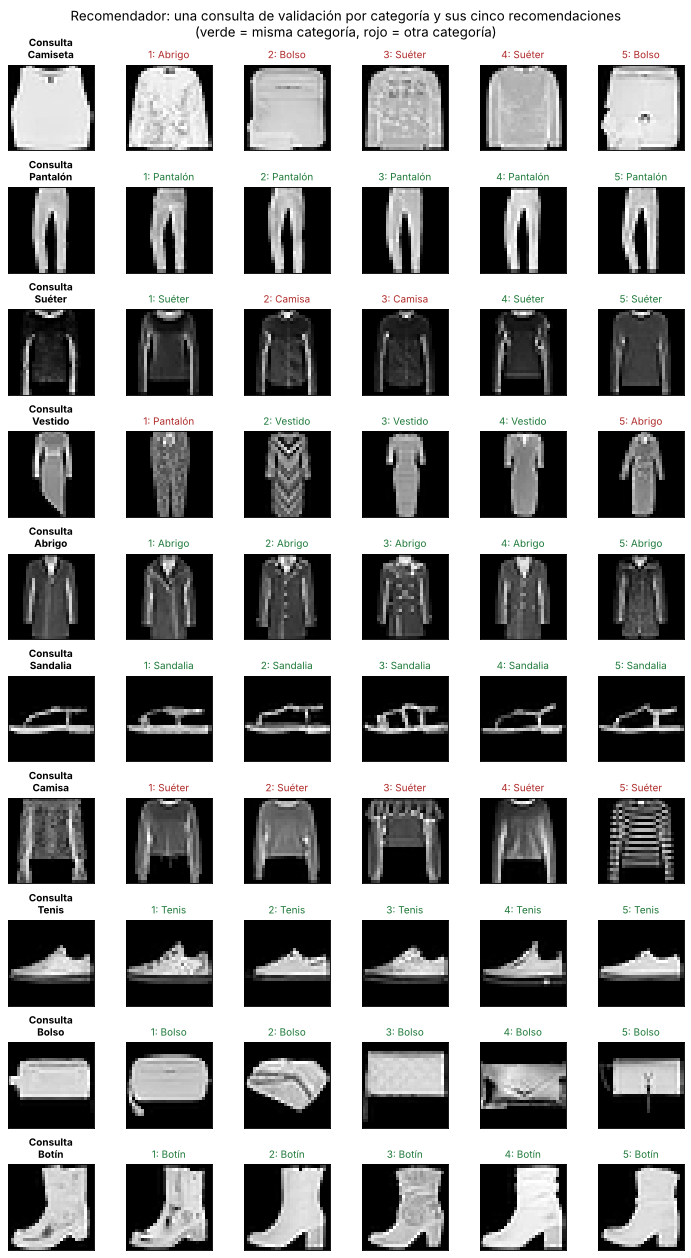

In [15]:
indice_pca_coseno = construir_recomendador(Z_train, metrica="cosine")

def recomendar_prendas(imagen, k=5):
    """Recibe una imagen 28 x 28 con píxeles entre 0 y 1 y devuelve posiciones del catálogo."""
    z = pca.transform(imagen.reshape(1, -1))
    return recomendar(indice_pca_coseno, z, k)[0]

def mostrar_recomendaciones(ejes_fila, imagen, categoria_consulta, posiciones):
    ejes_fila[0].imshow(imagen, cmap="gray", vmin=0, vmax=1)
    ejes_fila[0].set_title(f"Consulta\n{CATEGORIAS[categoria_consulta]}", fontsize=9, fontweight="bold")
    for j, p in enumerate(posiciones, start=1):
        acierto = y_train[p] == categoria_consulta
        ejes_fila[j].imshow(X_train[p], cmap="gray", vmin=0, vmax=1)
        ejes_fila[j].set_title(f"{j}: {CATEGORIAS[y_train[p]]}", fontsize=9,
                               color="#1f7a3a" if acierto else "#b02a2a")
    for eje in ejes_fila:
        eje.set_xticks([]); eje.set_yticks([])

# Una consulta de cada categoría, tomada de validación
rng = np.random.default_rng(SEMILLA)
fig, ejes = plt.subplots(10, 6, figsize=(9, 16))
for c in range(10):
    consulta = rng.choice(np.flatnonzero(y_val == c))
    mostrar_recomendaciones(ejes[c], X_val[consulta], y_val[consulta], recomendar_prendas(X_val[consulta]))
fig.suptitle("Recomendador: una consulta de validación por categoría y sus cinco recomendaciones\n"
             "(verde = misma categoría, rojo = otra categoría)")
fig.tight_layout()
guardar_figura(fig, "recomendador_ejemplos_validacion.png")
plt.show(); plt.close(fig)

## 11 Evaluación con Precision@5

**Precision@5** = de las cinco prendas recomendadas, qué fracción es de la misma categoría que la consulta. Se promedia sobre todas las consultas. Si se recomendara al azar, el valor esperado es 0.10 porque hay 10 categorías equilibradas.

### 11.1 Comparación de variantes en validación

Se comparan cuatro variantes con las 12,000 imágenes de validación como consultas. La que obtenga mayor Precision@5 aquí es la que se evaluará en prueba. Las categorías solo sirven para medir cada variante completa; no modifican qué prendas recomienda ninguna de ellas.

In [16]:
X_train_vec = X_train_flat
indice_pixeles = construir_recomendador(X_train_vec, metrica="cosine")
indice_pca_euclidiana = construir_recomendador(Z_train, metrica="euclidean")

VARIANTES = {
    "Píxeles 784 + coseno": lambda X, Z, G: recomendar(indice_pixeles, a_vectores(X), 5),
    "PCA 50 + euclidiana": lambda X, Z, G: recomendar(indice_pca_euclidiana, Z, 5),
    "PCA 50 + coseno": lambda X, Z, G: recomendar(indice_pca_coseno, Z, 5),
    "PCA 50 + coseno, mismo grupo K-Means": lambda X, Z, G: recomendar_mismo_grupo(Z_train, grupos_train, Z, G, 5),
}

def precision_aleatoria(y_consultas, repeticiones=5):
    valores = [precision_en_k(y_consultas, y_train,
                              recomendaciones_aleatorias(len(y_consultas), len(y_train), 5, semilla=SEMILLA + r))
               for r in range(repeticiones)]
    return float(np.mean(valores)), float(np.std(valores))

comparacion_val = []
for nombre, funcion in VARIANTES.items():
    inicio = time.time()
    posiciones = funcion(X_val, Z_val, grupos_val)
    p5 = precision_en_k(y_val, y_train, posiciones)
    comparacion_val.append({"variante": nombre, "precision_at_5": round(p5, 4),
                            "segundos": round(time.time() - inicio, 1)})
    print(f"{nombre:38} Precision@5 = {p5:.4f}")

media, desv = precision_aleatoria(y_val)
comparacion_val.append({"variante": "Aleatorio (media de 5 semillas)", "precision_at_5": round(media, 4), "segundos": 0})
print(f"{'Aleatorio (media de 5 semillas)':38} Precision@5 = {media:.4f} ± {desv:.4f}")
guardar_csv("recomendador_comparacion_validacion.csv", comparacion_val)

VARIANTE_ELEGIDA = max(comparacion_val[:-1], key=lambda f: f["precision_at_5"])["variante"]
print("\nVariante elegida con validación:", VARIANTE_ELEGIDA)

Píxeles 784 + coseno                   Precision@5 = 0.8283
PCA 50 + euclidiana                    Precision@5 = 0.8252
PCA 50 + coseno                        Precision@5 = 0.8321
PCA 50 + coseno, mismo grupo K-Means   Precision@5 = 0.8287
Aleatorio (media de 5 semillas)        Precision@5 = 0.1001 ± 0.0010

Variante elegida con validación: PCA 50 + coseno


### 11.2 Evaluación final en prueba

Se usa una sola vez, con la variante elegida en validación. Las 10,000 imágenes de prueba son las consultas y el catálogo sigue siendo entrenamiento. También se calcula la Precision@5 por categoría.

Prueba, PCA 50 + coseno: Precision@5 = 0.8211
Prueba, aleatorio (5 semillas): Precision@5 = 0.1002 ± 0.0016
Mejora sobre el azar: 8.2 veces

Categoría  | Recomendador | Aleatorio
Camiseta   |        0.761 |     0.095
Pantalón   |        0.963 |     0.104
Suéter     |        0.709 |     0.098
Vestido    |        0.832 |     0.103
Abrigo     |        0.714 |     0.106
Sandalia   |        0.873 |     0.103
Camisa     |        0.556 |     0.098
Tenis      |        0.910 |     0.097
Bolso      |        0.954 |     0.099
Botín      |        0.939 |     0.109


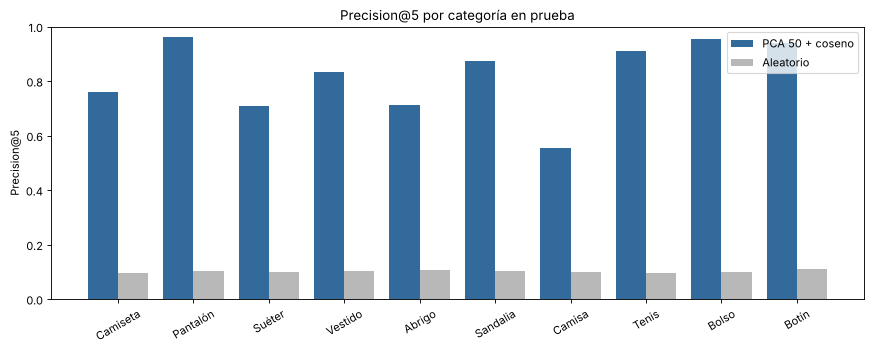

In [17]:
grupos_test = kmeans.predict(Z_test)
posiciones_test = VARIANTES[VARIANTE_ELEGIDA](X_test, Z_test, grupos_test)
aciertos_test = aciertos(y_test, y_train, posiciones_test)
p5_test = float(aciertos_test.mean())
media_azar, desv_azar = precision_aleatoria(y_test)
posiciones_azar = recomendaciones_aleatorias(len(y_test), len(y_train), 5, semilla=SEMILLA)
aciertos_azar = aciertos(y_test, y_train, posiciones_azar)

print(f"Prueba, {VARIANTE_ELEGIDA}: Precision@5 = {p5_test:.4f}")
print(f"Prueba, aleatorio (5 semillas): Precision@5 = {media_azar:.4f} ± {desv_azar:.4f}")
print(f"Mejora sobre el azar: {p5_test / media_azar:.1f} veces")

resultado_final = [
    {"conjunto": "prueba", "variante": VARIANTE_ELEGIDA, "precision_at_5": round(p5_test, 4)},
    {"conjunto": "prueba", "variante": "Aleatorio (media de 5 semillas)", "precision_at_5": round(media_azar, 4)},
]
guardar_csv("recomendador_resultado_prueba.csv", resultado_final)

por_categoria = []
print("\nCategoría  | Recomendador | Aleatorio")
for c in range(10):
    sel = y_test == c
    fila = {"id": c, "categoria": CATEGORIAS[c],
            "precision_at_5_recomendador": round(float(aciertos_test[sel].mean()), 4),
            "precision_at_5_aleatorio": round(float(aciertos_azar[sel].mean()), 4)}
    por_categoria.append(fila)
    print(f"{CATEGORIAS[c]:10} | {fila['precision_at_5_recomendador']:12.3f} | {fila['precision_at_5_aleatorio']:9.3f}")
guardar_csv("recomendador_precision_por_categoria_prueba.csv", por_categoria)

fig, ax = plt.subplots(figsize=(11, 4.5))
posiciones_x = np.arange(10)
ax.bar(posiciones_x - 0.2, [f["precision_at_5_recomendador"] for f in por_categoria], 0.4,
       label=VARIANTE_ELEGIDA, color="#326b9b")
ax.bar(posiciones_x + 0.2, [f["precision_at_5_aleatorio"] for f in por_categoria], 0.4,
       label="Aleatorio", color="#b8b8b8")
ax.set_xticks(posiciones_x, CATEGORIAS, rotation=30)
ax.set_ylim(0, 1); ax.set_ylabel("Precision@5")
ax.set_title("Precision@5 por categoría en prueba")
ax.legend()
fig.tight_layout()
guardar_figura(fig, "recomendador_precision_por_categoria.png")
plt.show(); plt.close(fig)

## 12 Ejemplos de aciertos y fallos

Arriba, consultas de prueba con las cinco recomendaciones correctas; abajo, consultas con más fallos. La tabla siguiente cuenta con qué categorías se confunden más las recomendaciones.

Consultas con 5 de 5 correctas: 63.9%
Consultas con 0 o 1 correctas: 9.5%

Confusiones más frecuentes (consulta -> recomendada):
  Camisa    -> Camiseta    871 (17.4%)
  Camiseta  -> Camisa      806 (16.1%)
  Abrigo    -> Suéter      694 (13.9%)
  Suéter    -> Abrigo      654 (13.1%)
  Suéter    -> Camisa      594 (11.9%)
  Camisa    -> Suéter      587 (11.7%)
  Abrigo    -> Camisa      540 (10.8%)
  Camisa    -> Abrigo      520 (10.4%)
  Sandalia  -> Tenis       362 (7.2%)
  Tenis     -> Botín       319 (6.4%)


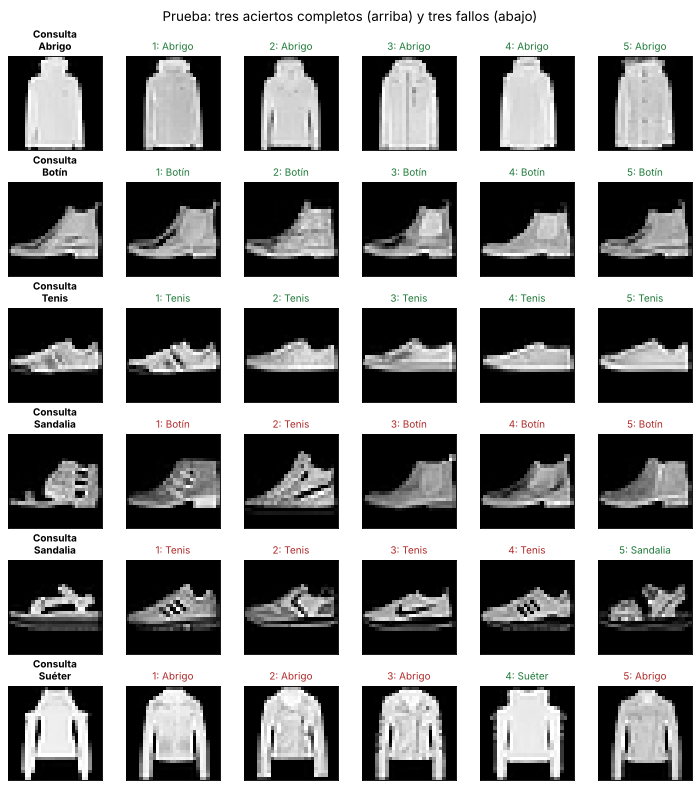

In [18]:
rng = np.random.default_rng(SEMILLA)
n_aciertos = aciertos_test.sum(axis=1)
buenos = rng.choice(np.flatnonzero(n_aciertos == 5), size=3, replace=False)
malos = rng.choice(np.flatnonzero(n_aciertos <= 1), size=3, replace=False)

fig, ejes = plt.subplots(6, 6, figsize=(9, 10))
for fila, consulta in enumerate(np.concatenate([buenos, malos])):
    mostrar_recomendaciones(ejes[fila], X_test[consulta], y_test[consulta], posiciones_test[consulta])
fig.suptitle("Prueba: tres aciertos completos (arriba) y tres fallos (abajo)")
fig.tight_layout()
guardar_figura(fig, "recomendador_aciertos_y_fallos.png")
plt.show(); plt.close(fig)

print(f"Consultas con 5 de 5 correctas: {np.mean(n_aciertos == 5):.1%}")
print(f"Consultas con 0 o 1 correctas: {np.mean(n_aciertos <= 1):.1%}")

confusiones = tabla_contingencia(np.repeat(y_test, 5), y_train[posiciones_test].ravel())
np.fill_diagonal(confusiones, 0)
pares = sorted(((confusiones[a, b], a, b) for a in range(10) for b in range(10) if confusiones[a, b] > 0), reverse=True)[:10]
filas_conf = [{"consulta": CATEGORIAS[a], "recomendada": CATEGORIAS[b], "recomendaciones": int(n),
               "porcentaje_de_la_categoria": round(100 * n / (5 * np.sum(y_test == a)), 1)} for n, a, b in pares]
guardar_csv("recomendador_confusiones_prueba.csv", filas_conf)
print("\nConfusiones más frecuentes (consulta -> recomendada):")
for f in filas_conf:
    print(f"  {f['consulta']:9} -> {f['recomendada']:9} {f['recomendaciones']:5} ({f['porcentaje_de_la_categoria']}%)")

## 13 Descargar los resultados

La siguiente celda crea un ZIP con las tablas y gráficas de esta parte. Extráelo dentro de la carpeta `resultados/` del repositorio. Descarga también este notebook ejecutado (Archivo > Descargar > `.ipynb`).

In [19]:
import zipfile

ruta_zip = Path("StyleBot_agrupamiento_generado.zip")
with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as comprimido:
    for ruta in sorted(CARPETA_SALIDA.rglob("*")):
        if ruta.is_file():
            comprimido.write(ruta, ruta.relative_to(CARPETA_SALIDA))
print("Archivo preparado:", ruta_zip.resolve())

try:
    from google.colab import files
except ImportError:
    print("Fuera de Colab: abre el ZIP en la ruta indicada arriba.")
else:
    files.download(str(ruta_zip))

## 14 Explicación

### Qué se hizo

- **Representación:** cada imagen se aplanó a 784 píxeles y se redujo a 50 componentes con PCA, igual que en `02_caracteristicas.ipynb`. PCA conserva cerca de 86 % de la varianza con 16 veces menos valores.
- **K-Means:** divide las imágenes en k grupos asignando cada una al centro más cercano y recalculando los centros hasta que se estabilizan. No usa las etiquetas. Se eligió k = 10 por las diez categorías y se revisaron la inercia y la silueta para otros valores de k.
- **t-SNE:** proyecta las 50 componentes a dos dimensiones conservando qué imágenes son vecinas. Se usó t-SNE en lugar de UMAP porque ya viene en scikit-learn y no agrega otra biblioteca al proyecto. Solo sirve para explorar visualmente.
- **Recomendador:** busca en el catálogo de entrenamiento las cinco prendas con menor distancia coseno a la consulta en el espacio PCA. Se compararon cuatro variantes en validación y se eligió la mejor antes de tocar la prueba.
- **Precision@5:** fracción de las cinco recomendaciones que es de la misma categoría que la consulta. Al azar se espera 0.10.

### Qué se observó (valores de esta ejecución)

- **K-Means** obtuvo pureza ≈ 0.55, ARI ≈ 0.35 y NMI ≈ 0.51, casi iguales en entrenamiento y validación. Los bolsos y los botines forman grupos limpios (más de 90 %). Pantalón y vestido comparten un grupo por su silueta alargada. Suéter, abrigo y camisa se mezclan. Un grupo junta prendas oscuras de distintas categorías, lo que indica que K-Means sobre píxeles también agrupa por brillo. La silueta es baja para todos los k (≈ 0.18 a 0.22), así que los grupos se traslapan.
- **t-SNE** muestra islas separadas para pantalones y bolsos, una región para el calzado y una zona compartida por camiseta, camisa, suéter, abrigo y vestido.
- **Recomendador:** en validación, PCA 50 + coseno fue la mejor variante (≈ 0.83). Usar los 784 píxeles o buscar solo dentro del mismo grupo de K-Means dio casi lo mismo. En prueba obtuvo **Precision@5 ≈ 0.82, contra 0.10 al azar (unas 8 veces mejor)**. En cerca de 64 % de las consultas las cinco recomendaciones son correctas.
- Funciona mejor con pantalón, bolso, botín y tenis (≥ 0.91) y peor con camisa (≈ 0.56). Las confusiones más comunes son camisa ↔ camiseta y abrigo ↔ suéter, prendas con casi la misma silueta en 28 x 28.

### Limitaciones

- Imágenes pequeñas y en escala de grises: la similitud depende de forma y brillo, no de color, textura fina o estilo.
- Precision@5 solo cuenta como correcta la misma categoría; una camisa parecida a una camiseta puede ser una buena recomendación aunque cuente como error.
- K-Means y t-SNE pueden cambiar ligeramente con otra versión de scikit-learn; los números deben leerse de la ejecución final.

## 15 Revisión con aprendizaje clásico

Comparación con `03_modelos.ipynb` (aprendizaje clásico) y `02_caracteristicas.ipynb` (características):

| Punto | 02 características | 03 modelos | 04 no supervisado | Estado |
|---|---|---|---|---|
| Celda común de carga idéntica a `01_datos` | Sí | Sí | Sí | Correcto |
| Huella de la división de entrenamiento `1c0cffec…` | Sí | Sí | Sí (sección 5) | Correcto |
| Orden de etiquetas (0 = Camiseta, 6 = Camisa) | Sí | Sí | Sí | Correcto |
| PCA ajustado solo con entrenamiento | Sí | Sí | Sí | Correcto |
| Componentes de PCA | 50 (86.3 %) | **100** (91.2 %) | 50 (86.3 %) | Diferente: documentar |
| Prueba usada solo para la evaluación final | — | Sí, el modelo se elige por validación cruzada | Sí, la variante se elige por validación | Correcto |

La única diferencia es el número de componentes de PCA. No invalida ninguna parte, porque cada notebook ajusta su PCA solo con entrenamiento, pero el informe debe indicar que la clasificación usa 100 componentes y el agrupamiento y el recomendador usan 50. Si el equipo prefiere unificar, en este notebook basta cambiar el `50` de la sección 7.

## Fuentes

- Scikit-learn. KMeans. https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
- Scikit-learn. PCA. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
- Scikit-learn. TSNE. https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html
- Scikit-learn. NearestNeighbors. https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NearestNeighbors.html
- Scikit-learn. Evaluación de agrupamiento (ARI, NMI, silueta). https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation
- Manning, Raghavan y Schütze (2008). Introduction to Information Retrieval, cap. 8 (precisión en los primeros k resultados). https://nlp.stanford.edu/IR-book/
- Van der Maaten y Hinton (2008). Visualizing Data using t-SNE. Journal of Machine Learning Research, 9.
- Equipo StyleBot. `02_caracteristicas.ipynb` (aplanado y PCA reutilizados) y `01_datos.ipynb` (carga común).
- Xiao, Rasul y Vollgraf (2017). Fashion-MNIST. https://github.com/zalandoresearch/fashion-mnist